In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

In [2]:
CHARACTERS = "ABCDEFGHJKLMNPQRSTUVWXYZ23456789"

CAPTCHA_LENGTH = 5

CHAR_WIDTH = 50
CHAR_HEIGHT = 60

IMAGE_WIDTH = CAPTCHA_LENGTH * CHAR_WIDTH
IMAGE_HEIGHT = CHAR_HEIGHT

print("Characters:", CHARACTERS)
print("CAPTCHA length:", CAPTCHA_LENGTH)

Characters: ABCDEFGHJKLMNPQRSTUVWXYZ23456789
CAPTCHA length: 5


In [3]:
def load_font():
    font_paths = [
        "C:/Windows/Fonts/arial.ttf",
        "C:/Windows/Fonts/arialbd.ttf",
        "DejaVuSans-Bold.ttf"
    ]

    for path in font_paths:
        try:
            return ImageFont.truetype(path, 34)
        except OSError:
            continue

    return ImageFont.load_default()


font = load_font()

In [4]:
def generate_captcha():

    text = "".join(
        random.choices(CHARACTERS, k=CAPTCHA_LENGTH)
    )

    image = Image.new(
        "RGB",
        (IMAGE_WIDTH, IMAGE_HEIGHT),
        "white"
    )

    for i, char in enumerate(text):

        char_image = Image.new(
            "RGB",
            (CHAR_WIDTH, CHAR_HEIGHT),
            "white"
        )

        draw = ImageDraw.Draw(char_image)

        bbox = draw.textbbox((0, 0), char, font=font)

        text_width = bbox[2] - bbox[0]
        text_height = bbox[3] - bbox[1]

        x = (CHAR_WIDTH - text_width) // 2
        y = (CHAR_HEIGHT - text_height) // 2 - bbox[1]

        draw.text(
            (x, y),
            char,
            fill="black",
            font=font
        )

        char_image = char_image.rotate(
            random.randint(-12, 12),
            fillcolor="white"
        )

        image.paste(
            char_image,
            (i * CHAR_WIDTH, 0)
        )

    draw = ImageDraw.Draw(image)

    # Add random noise lines
    for _ in range(4):

        x1 = random.randint(0, IMAGE_WIDTH)
        y1 = random.randint(0, IMAGE_HEIGHT)

        x2 = random.randint(0, IMAGE_WIDTH)
        y2 = random.randint(0, IMAGE_HEIGHT)

        draw.line(
            (x1, y1, x2, y2),
            fill="gray",
            width=1
        )

    return image, text

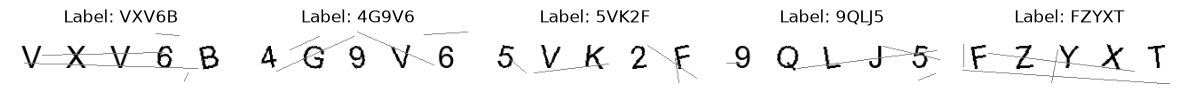

In [5]:
plt.figure(figsize=(12, 4))

for i in range(5):

    image, text = generate_captcha()

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)

    plt.title("Label: " + text)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
def segment_characters(image):

    characters = []

    for i in range(CAPTCHA_LENGTH):

        left = i * CHAR_WIDTH
        right = left + CHAR_WIDTH

        char_image = image.crop(
            (left, 0, right, CHAR_HEIGHT)
        )

        char_image = char_image.convert("L")

        characters.append(char_image)

    return characters

In [7]:
X = []
y = []

for _ in range(3000):

    image, text = generate_captcha()

    char_images = segment_characters(image)

    for char_image, label in zip(char_images, text):

        image_array = np.array(char_image)

        X.append(image_array)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Image dataset shape:", X.shape)
print("Label dataset shape:", y.shape)

Image dataset shape: (15000, 60, 50)
Label dataset shape: (15000,)


In [8]:
X = X.astype("float32") / 255.0

X = X.reshape(
    -1,
    CHAR_HEIGHT,
    CHAR_WIDTH,
    1
)

print("Processed image shape:", X.shape)

Processed image shape: (15000, 60, 50, 1)


In [9]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Number of character classes:", len(encoder.classes_))
print("Character classes:", encoder.classes_)

Number of character classes: 32
Character classes: ['2' '3' '4' '5' '6' '7' '8' '9' 'A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'J' 'K'
 'L' 'M' 'N' 'P' 'Q' 'R' 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 12000
Testing samples: 3000


In [11]:
model = models.Sequential([

    layers.Input(
        shape=(CHAR_HEIGHT, CHAR_WIDTH, 1)
    ),

    # First convolution block
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.4),

    layers.Dense(
        len(encoder.classes_),
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 58, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 29, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 27, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 9, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2560)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       327,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,608 (1.62 MB)

 Trainable params: 424,608 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [13]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.20,
    verbose=1
)

Epoch 1/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.6651 - loss: 1.1745 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 2/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9903 - loss: 0.0364 - val_accuracy: 1.0000 - val_loss: 1.1509e-04
Epoch 3/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9912 - loss: 0.0265 - val_accuracy: 1.0000 - val_loss: 1.1788e-05
Epoch 4/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9958 - loss: 0.0138 - val_accuracy: 1.0000 - val_loss: 3.6042e-06
Epoch 5/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9955 - loss: 0.0136 - val_accuracy: 1.0000 - val_loss: 2.6989e-05
Epoch 6/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9972 - loss: 0.0086 - val_accuracy: 1.0000 - val_loss: 8.1559e-08
Epoch 7/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9958 - loss: 0.0130 - val_accuracy: 1.0000 - val_loss: 5.3903e-06
Epoch 8/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9973 -

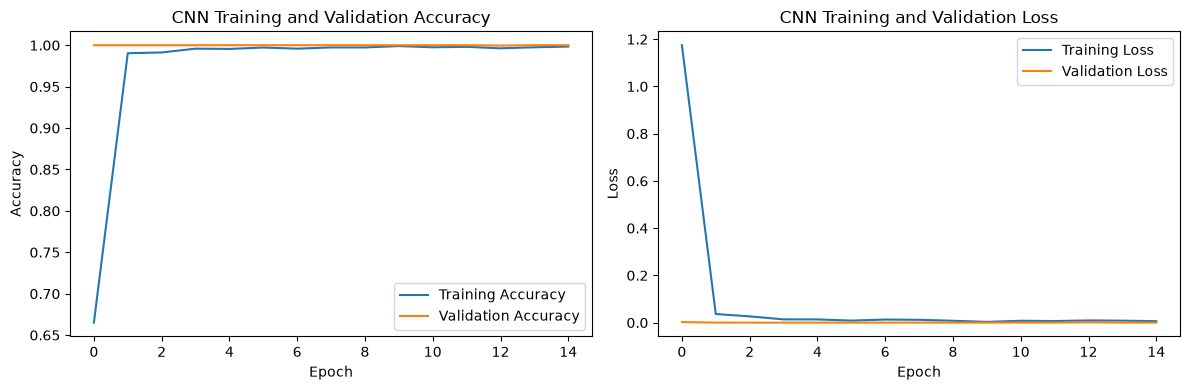

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))

print(
    "Character Recognition Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

Test Loss: 0.0
Character Recognition Accuracy: 100.0 %


In [16]:
y_probabilities = model.predict(X_test)

y_pred = np.argmax(
    y_probabilities,
    axis=1
)

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(encoder.classes_)),
        target_names=encoder.classes_,
        zero_division=0
    )
)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
              precision    recall  f1-score   support

           2       1.00      1.00      1.00        89
           3       1.00      1.00      1.00        97
           4       1.00      1.00      1.00        89
           5       1.00      1.00      1.00        97
           6       1.00      1.00      1.00        92
           7       1.00      1.00      1.00        94
           8       1.00      1.00      1.00        90
           9       1.00      1.00      1.00        92
           A       1.00      1.00      1.00       102
           B       1.00      1.00      1.00        91
           C       1.00      1.00      1.00        95
           D       1.00      1.00      1.00        95
           E       1.00      1.00      1.00        97
           F       1.00      1.00      1.00        96
           G       1.00      1.00      1.00        92
           H       1.00      1.00      1.00        93
           J       1.00      1.00      1.0

In [17]:
def solve_captcha(image):

    char_images = segment_characters(image)

    predicted_text = ""

    for char_image in char_images:

        image_array = np.array(char_image)

        image_array = image_array.astype("float32") / 255.0

        image_array = image_array.reshape(
            1,
            CHAR_HEIGHT,
            CHAR_WIDTH,
            1
        )

        prediction = model.predict(
            image_array,
            verbose=0
        )

        predicted_index = np.argmax(prediction)

        predicted_char = encoder.inverse_transform(
            [predicted_index]
        )[0]

        predicted_text += predicted_char

    return predicted_text

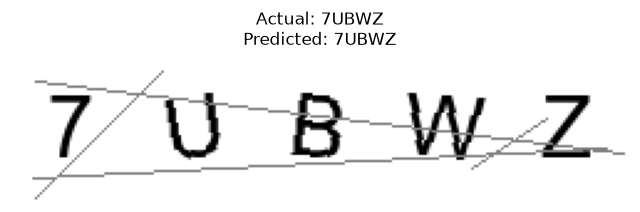

Actual CAPTCHA: 7UBWZ
Predicted CAPTCHA: 7UBWZ


In [18]:
test_image, actual_text = generate_captcha()

predicted_text = solve_captcha(test_image)

plt.figure(figsize=(8, 3))

plt.imshow(test_image)

plt.title(
    "Actual: " + actual_text +
    "\nPredicted: " + predicted_text
)

plt.axis("off")
plt.show()

print("Actual CAPTCHA:", actual_text)
print("Predicted CAPTCHA:", predicted_text)

In [19]:
correct = 0
total = 100

for _ in range(total):

    image, actual_text = generate_captcha()

    predicted_text = solve_captcha(image)

    if predicted_text == actual_text:
        correct += 1

captcha_accuracy = (correct / total) * 100

print(
    "Complete CAPTCHA Recognition Accuracy:",
    round(captcha_accuracy, 2),
    "%"
)

Complete CAPTCHA Recognition Accuracy: 100.0 %
